# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

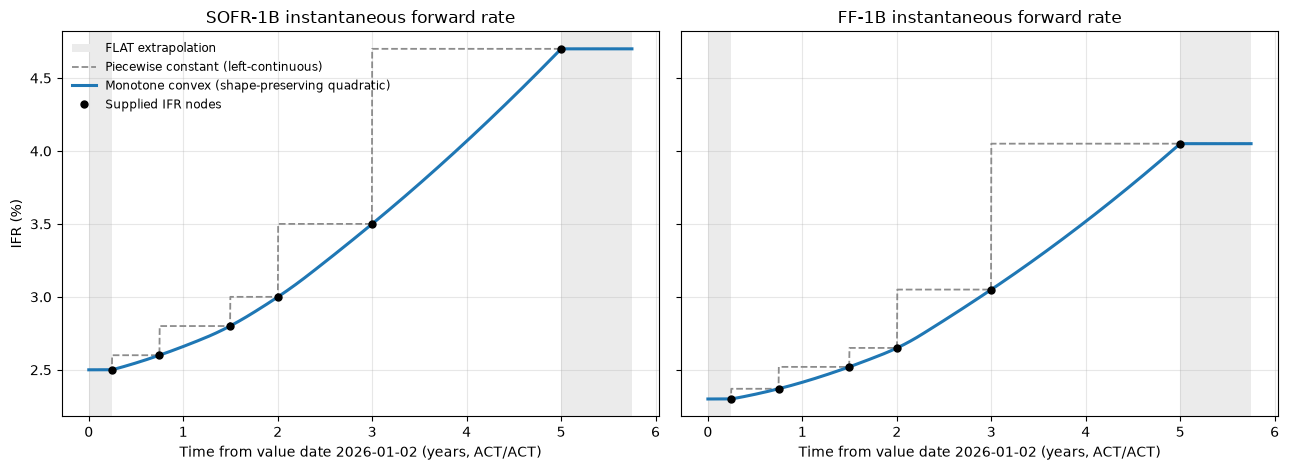

SOFR-1B: passes through nodes=True, monotone=True, no overshoot=True, convex=True (on every interval)
FF-1B: passes through nodes=True, monotone=True, no overshoot=True, convex=True (on every interval)
SOFR-1B-FLAT (one node) is constant: True


In [2]:
# IFR curves: MONOTONE_CONVEX vs PIECEWISE_CONSTANT_LEFT_CONTINUOUS (same supplied nodes, FLAT extrapolation)
import numpy as np
import matplotlib.pyplot as plt

def build_ifr_model(interp_method):
    """Build the YIELD_CURVE model exactly as the pricing cells do, for a given interpolation method."""
    bm = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs,
                                   "INTERPOLATION METHOD": interp_method,
                                   "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs
    ])
    return qfCreateModel("2026-01-02", "YIELD_CURVE", data_collection, bm)

models = {"MONOTONE_CONVEX": build_ifr_model("MONOTONE_CONVEX"),
          "PIECEWISE_CONSTANT_LEFT_CONTINUOUS": build_ifr_model("PIECEWISE_CONSTANT_LEFT_CONTINUOUS")}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, curve in zip(axes, ["SOFR-1B", "FF-1B"]):
    mc = models["MONOTONE_CONVEX"].retrieve_model_component(curve)
    pcp = models["PIECEWISE_CONSTANT_LEFT_CONTINUOUS"].retrieve_model_component(curve)
    t_nodes = np.asarray(mc.state_data[0], dtype=float)   # ACT/ACT years from the value date
    f_nodes = np.asarray(mc.state_data[1], dtype=float)
    t = np.linspace(0.0, t_nodes[-1] + 0.75, 2000)

    ax.axvspan(0.0, t_nodes[0], color="0.92", lw=0)
    ax.axvspan(t_nodes[-1], t[-1], color="0.92", lw=0, label="FLAT extrapolation")
    ax.plot(t, [100 * pcp.state_data_interpolator.interpolate(x) for x in t],
            color="0.55", lw=1.3, ls="--", label="Piecewise constant (left-continuous)")
    ax.plot(t, [100 * mc.state_data_interpolator.interpolate(x) for x in t],
            color="tab:blue", lw=2.2, label="Monotone convex (shape-preserving quadratic)")
    ax.plot(t_nodes, 100 * f_nodes, "o", color="black", ms=5, zorder=5, label="Supplied IFR nodes")
    ax.set_title(f"{curve} instantaneous forward rate")
    ax.set_xlabel("Time from value date 2026-01-02 (years, ACT/ACT)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("IFR (%)")
axes[0].legend(loc="upper left", fontsize=8.5, frameon=False)
plt.tight_layout()
plt.show()

# Numerical check of the shape claims on a fine grid inside every node interval.
for curve in ["SOFR-1B", "FF-1B"]:
    comp = models["MONOTONE_CONVEX"].retrieve_model_component(curve)
    ip = comp.state_data_interpolator
    t_nodes = np.asarray(comp.state_data[0], dtype=float)
    f_nodes = np.asarray(comp.state_data[1], dtype=float)
    hits_nodes = all(abs(ip.interpolate(x) - y) < 1e-14 for x, y in zip(t_nodes, f_nodes))
    monotone = no_overshoot = convex = True
    for i in range(len(t_nodes) - 1):
        grid = np.linspace(t_nodes[i], t_nodes[i + 1], 1001)
        vals = np.array([ip.interpolate(x) for x in grid])
        direction = np.sign(f_nodes[i + 1] - f_nodes[i])           # +1 rising, -1 falling, 0 flat
        steps = np.diff(vals)
        monotone &= bool(np.all(steps * direction >= -1e-14) if direction != 0 else np.all(np.abs(steps) <= 1e-14))
        lo, hi = sorted((f_nodes[i], f_nodes[i + 1]))
        no_overshoot &= bool(vals.min() >= lo - 1e-14 and vals.max() <= hi + 1e-14)
        convex &= bool(np.all(np.diff(vals, 2) >= -1e-14))
    print(f"{curve}: passes through nodes={hits_nodes}, monotone={monotone}, "
          f"no overshoot={no_overshoot}, convex={convex} (on every interval)")

funding = models["MONOTONE_CONVEX"].retrieve_model_component("SOFR-1B-FLAT").state_data_interpolator
print("SOFR-1B-FLAT (one node) is constant:",
      all(abs(funding.interpolate(x) - 0.0005) < 1e-15 for x in [0.0, 0.5, 1.0, 3.0, 10.0]))

### Method: shape-preserving piecewise-quadratic IFR interpolator

**Inputs and goal.** The supplied data are *pointwise* instantaneous forward rates $f_i$ at node times $x_i$ (ACT/ACT years from the value date). The interpolator must define $f(x)$ everywhere, because discount factors are $P(0,T)=\exp\!\left(-\int_0^T f(t)\,dt\right)$ and forwards also come from $\int f$. So `integrate` drives every PV and is computed exactly.

**Why this method.** I compared four candidates on the supplied curves and on stress data:

| Method | Problem |
|---|---|
| Piecewise constant (left-continuous) | Forward jumps at every node; on a rising curve it uses the right node's rate across the whole interval, overstating forwards between nodes |
| Linear | Monotone and (weakly) convex, but kinks at every node |
| Natural cubic spline | Smooth, but can overshoot the data and is non-local (one bumped node moves the whole curve) |
| **Shape-preserving quadratic (chosen)** | Monotone and convex on each interval by construction, local, smooth wherever the selected slopes allow |

The construction follows Schumaker's (1983) shape-preserving quadratic spline. The design criteria follow Hagan & West (2006): positive, continuous and stable forwards; locality; smoothness only where it does not compromise the other criteria. I did not use Hagan & West's monotone convex algorithm directly: it takes interval-*average* forwards and preserves their integrals, whereas these inputs are pointwise values the curve must pass through.

**Construction.** Let $h_i = x_{i+1}-x_i$ and $s_i = (f_{i+1}-f_i)/h_i$ (the secant slope).

1. *Node slopes.* At interior nodes, a weighted three-point estimate $\dfrac{h_i s_{i-1} + h_{i-1} s_i}{h_{i-1}+h_i}$; at the two end nodes, a one-sided three-point estimate. Each slope is clipped so that, on every interval, the left-end slope $a$ and right-end slope $b$ satisfy $a \le s_i \le b$, and both share the sign of $s_i$. If no single slope at a node satisfies both neighbouring intervals, each side uses its own secant.
2. *Interval shape.* If $a < s_i < b$ strictly, the interval is two quadratic pieces joined at $\xi = x_i + \lambda h_i$ with $\lambda = \dfrac{b-s_i}{b-a}$ (where the two end tangents meet). Otherwise it is the straight line with slope $s_i$.
3. *Integral.* Each piece is a polynomial, so its integral is closed-form. Cumulative areas at the nodes are stored once; `integrate(a, b)` $= F(b)-F(a)$, including the FLAT regions.

**How monotonicity and convexity are ensured.** On each quadratic interval, $f'$ is piecewise linear and runs $a \to s_i \to b$. Because $a \le s_i \le b$, $f'$ never decreases, so $f'' \ge 0$ and the interval is **convex**. Because $f'$ stays between $a$ and $b$, which share the sign of $s_i$, $f$ never reverses direction, so the interval is **monotone** and never overshoots its two node values. The choice of $\lambda$ makes the curve land exactly on $f_{i+1}$. When $a = s_i$ or $b = s_i$, convexity forces $f'$ to be constant (the secant is the average of $f'$), so the straight line is the only valid shape. The printed checks above confirm node reproduction, monotonicity and convexity on every interval for SOFR and FF.

**Data that cannot satisfy everything.**

| Data | Treatment |
|---|---|
| Secants increasing (the supplied SOFR and FF curves) | Quadratic pieces everywhere; no derivative jumps at interior nodes |
| Flat interval | Constant piece |
| Peak, or rising-but-flattening data (secants decreasing) | Derivative jump at those nodes; affected pieces become straight lines rather than forced curves |
| Two nodes | Straight line |
| One node (`SOFR-1B-FLAT`) | Constant |
| Repeated node times | Rejected with an error |

The principle: never invent structure. Continuity, node values, monotonicity and convexity are always kept; only smoothness is given up when the data cannot support it.

**Ends and extrapolation.** The first quoted rate is extrapolated flat back to time zero and the last quoted rate flat beyond the final node. Inside the first and last interpolation intervals, the slope is a one-sided estimate from the nearest quotes, so the curve near the ends reflects the data rather than the extrapolation convention. The forward rate is continuous at both end nodes, where its derivative may jump.

**Guarantee.** The interpolator is continuous, reproduces the supplied instantaneous forward rates at the nodes, and is monotone and convex on each node interval. It uses two quadratic pieces when the selected endpoint slopes strictly bracket the interval secant and a straight line otherwise. The first derivative may jump at nodes and where the interpolator meets flat extrapolation. All pieces are integrated analytically.

**Limitations.** A node's slope uses its neighbours on both sides, so the curve just before node $i$ depends slightly on node $i+1$; a node-by-node bootstrap would need a joint (e.g. Newton) solve instead. Bumping one node changes the IFR only on nearby intervals, but discount factors beyond it still move because they accumulate area. Non-negative node values give non-negative forwards and hence non-increasing discount factors; this is not a general no-arbitrage claim.


In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3261.7155818210267
Student minus PCP: 353.42894258306296


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513069528


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12844.059560238835
Student minus PCP: 6621.542047169307


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7623.300938491819
Student minus PCP: -728.0479696901748


In [9]:
# Average IFR over each product's accrual window: (1/T) * integral of f, PCP vs MONOTONE_CONVEX
from fixedincomelib.date import Date, accrued

value_date = Date("2026-01-02")
def t_of(d):
    return accrued(value_date, Date(d))   # same ACT/ACT convention the library uses for the IFR nodes

def avg_ifr(model_name, curve, start, end):
    ip = models[model_name].retrieve_model_component(curve).state_data_interpolator
    a, b = t_of(start), t_of(end)
    return ip.integrate(a, b) / (b - a)

windows = [("FRA",          "SOFR-1B", "2026-05-05", "2026-11-05"),
           ("Swap year 1",  "SOFR-1B", "2026-04-02", "2027-04-02"),
           ("Swap year 2",  "SOFR-1B", "2027-04-02", "2028-04-03"),
           ("Swap year 3",  "SOFR-1B", "2028-04-03", "2029-04-02"),
           ("Basis, SOFR leg", "SOFR-1B", "2026-07-02", "2028-07-03"),
           ("Basis, FF leg",   "FF-1B",   "2026-07-02", "2028-07-03")]
rows = []
for label, curve, start, end in windows:
    pcp = avg_ifr("PIECEWISE_CONSTANT_LEFT_CONTINUOUS", curve, start, end)
    mc = avg_ifr("MONOTONE_CONVEX", curve, start, end)
    rows.append({"window": label, "curve": curve, "PCP (%)": round(100 * pcp, 3),
                 "Monotone convex (%)": round(100 * mc, 3), "MC - PCP (bp)": round(1e4 * (mc - pcp), 1)})
fwd_table = pd.DataFrame(rows).set_index("window")
spread_pcp = fwd_table.loc["Basis, SOFR leg", "PCP (%)"] - fwd_table.loc["Basis, FF leg", "PCP (%)"]
spread_mc = fwd_table.loc["Basis, SOFR leg", "Monotone convex (%)"] - fwd_table.loc["Basis, FF leg", "Monotone convex (%)"]
print(fwd_table.to_string())
print(f"\nAverage SOFR - FF spread over the basis swap: PCP {100*spread_pcp:.1f}bp, monotone convex {100*spread_mc:.1f}bp")

                   curve  PCP (%)  Monotone convex (%)  MC - PCP (bp)
window                                                               
FRA              SOFR-1B    2.637                2.566           -7.0
Swap year 1      SOFR-1B    2.700                2.604           -9.6
Swap year 2      SOFR-1B    3.074                2.902          -17.2
Swap year 3      SOFR-1B    3.797                3.369          -42.8
Basis, SOFR leg  SOFR-1B    2.999                2.834          -16.5
Basis, FF leg      FF-1B    2.666                2.539          -12.6

Average SOFR - FF spread over the basis swap: PCP 33.3bp, monotone convex 29.5bp


### PV comparison: monotone convex vs piecewise constant

| Product | PCP PV | Monotone convex PV | Difference |
|---|---|---|---|
| FRA (receive 3.2% fixed) | 2,908.29 | 3,261.72 | **+353.43** |
| RFR swap (receive 3.4% fixed, 3y) | 6,222.52 | 12,844.06 | **+6,621.54** |
| Overnight basis swap (receive SOFR + 10bp, pay FF, 2y) | 8,351.35 | 7,623.30 | **−728.05** |

**Common cause.** Both runs use the same IFR node values; only the curve between nodes differs. The left-continuous piecewise-constant curve holds each interval at its *right* node's rate, so it lies above the quadratic interpolator between nodes on these rising curves (visible in the plot). The monotone convex curve rises gradually from one node to the next, so average forwards over every accrual window are lower (table above).

**FRA (+353).** The FRA accrual period (May 5 – November 5, 2026) crosses the October 2 node. PCP uses 2.6% up to that node and 2.8% afterward, giving an average of 2.637%. The quadratic interpolator rises from about 2.52% to 2.62% over the same period, passing through the 2.6% node, and lowers the average IFR to 2.566%, about 7bp. This lowers the projected floating payment and raises the receive-fixed PV by 353.43 (roughly 7bp × 0.51 years × 1,000,000 ≈ 358, discounted ≈ 350).

**RFR swap (+6,622).** The same effect accumulates over three annual periods, with average forwards lower by about 10bp, 17bp and 43bp. Year 3 (2028–2029) dominates: it spans the 2029 node, so PCP applies 3.5% and then 4.7% across whole intervals, while the new curve rises gradually from about 3.1% to 3.6% across the period, passing through the 3.5% node. The total floating-leg overstatement under PCP is about 0.7% of notional, which roughly doubles the receive-fixed PV.

**Overnight basis swap (−728).** Both legs fall, so what matters is the SOFR − FF spread. SOFR's nodes rise faster than FF's, so holding each interval at the right node's rate inflates SOFR more than FF. The average spread over the swap narrows from about 33.3bp to 29.5bp. Receiving SOFR + 10bp against FF on a narrower spread is worth less: roughly −3.8bp × 2 years × 1,000,000 ≈ −770, discounted ≈ −730.

**Discounting.** Discount factors also change, because the funding curve `SOFR-1B-FLAT` is SOFR plus a constant 0.05% and SOFR's integral is lower under the new method. The discounting effect is small relative to the projection effect in these examples. An approximate re-pricing with discounting held at the PCP curve attributes about +1 (FRA), +22 (swap) and +13 (basis) to discounting; almost all of each difference comes from the projected forwards.

**Takeaway.** No calibration was done: the same IFR quotes were interpolated two ways. Piecewise constant sets the forward equal to the next quote across each interval, so on these rising curves it lies at or above the quadratic interpolator between nodes, which raises projected forwards. With the IFR nodes held fixed and no recalibration, the PV differences measure sensitivity to the interpolation method. A comparison of calibrated curves would require refitting the nodes under each method.